# Code for Task 3 : Figure 3
Since the shot style figure was made with the season 2022-2023, let's do that figure with that season too.

In [69]:
from ift6758.features.simple_visualizations import games_list,distance
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

In [ ]:
df2022 = games_list(2022)
df_dist = distance(df2022)

In [75]:
# Code copied and modified from shot_style.ipynb

# Copy to avoid pandas warnings when adding a column
df_dist = df_dist.copy()

# Create a boolean column to know if the event is a goal
df_dist["is_goal"] = df_dist["event_type"] == "goal"

# Group by shot type: size counts all the shots (goals included) and sum counts the goals
# calculate the distance's mean for each shot type
df_shots_count = df_dist.groupby("shot_type")["is_goal"].agg(["size"])
df_shots_count = df_shots_count.rename(columns={"size": "shots"})

df_shots_dist = df_dist.groupby("shot_type")["distance"].agg(["mean"])
df_shots_dist = df_shots_dist.rename(columns={"mean": "distance_shots"})

df_shots = pd.concat([df_shots_count,df_shots_dist],axis=1)

df_goals_count = df_dist.groupby("shot_type")["is_goal"].agg(["sum"])
df_goals_count = df_goals_count.rename(columns={"sum": "goals"})

df_goals_dist = df_dist[df_dist["is_goal"]==True].groupby("shot_type")["distance"].agg(["mean"])
df_goals_dist = df_goals_dist.rename(columns={"mean": "distance_goals"})

df_goals = pd.concat([df_goals_count,df_goals_dist],axis=1)

df_merge = pd.concat([df_shots,df_goals], axis=1)

# Percentage of shots that became goals
df_merge["pct"] = df_merge["goals"] / df_merge["shots"] * 100

df_merge = df_merge.drop(
    columns = ["shots","goals"]
)

df_merge

,distance_shots,distance_goals,pct
shot_type,,,
backhand,19.886448,12.676321,11.191902
bat,15.397569,8.038913,25.592417
between-legs,9.901557,8.612333,15.384615
cradle,5.802776,3.605551,50.000000
deflected,20.646325,12.119590,16.929699
poke,12.150525,10.901354,15.402844
slap,47.607481,37.687883,7.509449
snap,34.207925,24.488220,11.827200
tip-in,18.700796,12.231976,15.857492


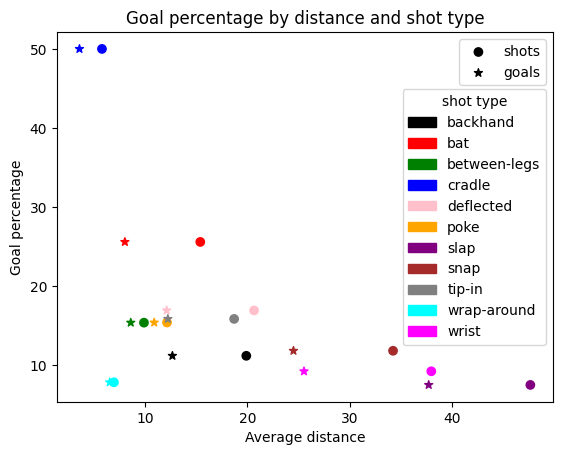

In [ ]:
X_shots = df_merge["distance_shots"]
Y_shots = df_merge["pct"]

# X_goals = df_merge["distance_goals"]
# Y_goals = df_merge["pct"]

colors = np.array(["black","red","green","blue","pink","orange","purple","brown","gray","cyan","magenta"])


shots = plt.scatter(X_shots,Y_shots,c=colors)
# goals = plt.scatter(X_goals,Y_goals,marker="*",c=colors)

plt.title("Goal percentage by distance and shot type")
plt.xlabel("Average distance")
plt.ylabel("Goal percentage")

legend = plt.legend([shots,goals],["shots","goals"],loc=1)

couleurs = {'backhand' : 'black', 
            'bat' : 'red', 
            'between-legs' : 'green', 
            'cradle' : 'blue', 
            'deflected' : 'pink', 
            'poke' : 'orange',
            'slap' : 'purple', 
            'snap' : 'brown', 
            'tip-in' : 'gray', 
            'wrap-around' : 'cyan', 
            'wrist' : 'magenta'}
legend2 = [
    mpatches.Patch(color=couleur,label=shot_type)
    for shot_type, couleur in couleurs.items()
]
plt.legend(handles=legend2,title="shot type",loc="center right")


plt.gca().add_artist(legend)
plt.show()

Briefly discuss your findings; e.g. what might be the most dangerous types of shots?

Comme attendu, la distance des tirs est toujours plus grande que la distances des buts.

On peut observer différents écarts entre la distance moyenne des buts et celles des tirs.

On peut notamment conclure que le wrap-around est un type de tirs qui se fait à une petite distance, que cela fasse un but ou non.

On peut réaffirmer aussi qu'il y a plus de chance de faire un buts à partir d'une petite distance, qu'une grande distance.

Le type de tir le plus dangereux est le cradle, avec 50% de buts. Ensuite, ce serait le bat.
